 AI-DRIVEN AVALANCHE SUSCEPTIBILITY PREDICTION SYSTEM

1. DATASET GENERATED SUCCESSFULLY!
   Temperature   Snowfall  Wind_Speed  Slope_Angle  Snow_Depth   Humidity  \
0   -13.763796  67.270299   64.825695    55.678901  167.033517  59.973619   
1     3.521429  79.668140   17.238636    36.268024   29.207817  79.739742   
2    -3.040182  25.046790   87.239456    46.245514   68.159155  65.013342   
3    -7.040245  62.487410   61.311624    31.802415  195.683043  26.664207   
4   -20.319441  57.174598   15.720388    41.501729  136.884605  34.846419   

   Recent_Snowfall Susceptibility  
0        32.284533           High  
1        20.120925       Moderate  
2        23.595455       Moderate  
3        35.836239       Moderate  
4        43.815301       Moderate  

2. TRAINING MACHINE LEARNING MODEL...

3. MODEL EVALUATION
Model Accuracy: 76.83 %

Classification Report:
              precision    recall  f1-score   support

        High       0.74      0.38      0.50        73
         Low  

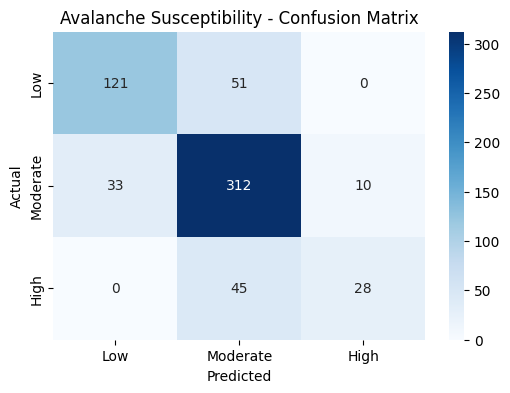

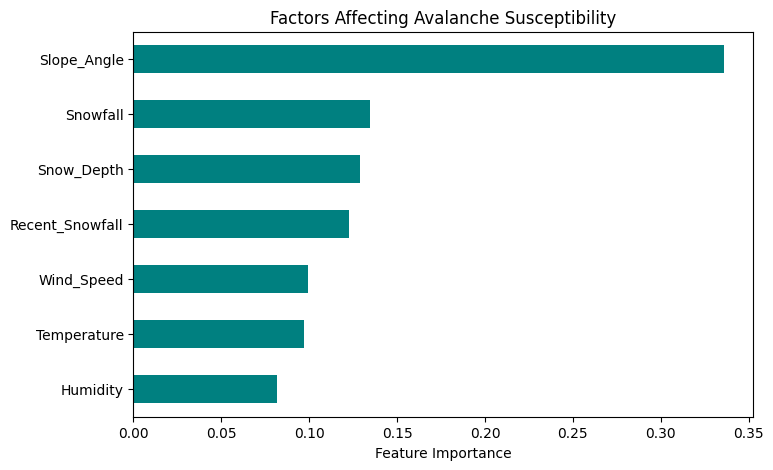


       AVALANCHE DECISION SUPPORT SYSTEM

Enter Environmental Conditions:


In [ ]:

# ============================================================
# AI-DRIVEN DECISION SUPPORT FOR AVALANCHE SUSCEPTIBILITY
# Complete One-Cell Google Colab Implementation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings("ignore")

print("=" * 65)
print(" AI-DRIVEN AVALANCHE SUSCEPTIBILITY PREDICTION SYSTEM")
print("=" * 65)

# 1. GENERATE SYNTHETIC AVALANCHE DATASET
np.random.seed(42)
n = 3000

data = pd.DataFrame({
    "Temperature": np.random.uniform(-25, 5, n),
    "Snowfall": np.random.uniform(0, 100, n),
    "Wind_Speed": np.random.uniform(0, 100, n),
    "Slope_Angle": np.random.uniform(10, 60, n),
    "Snow_Depth": np.random.uniform(10, 250, n),
    "Humidity": np.random.uniform(20, 100, n),
    "Recent_Snowfall": np.random.uniform(0, 50, n)
})

# Create synthetic susceptibility labels
risk_score = (
    data["Snowfall"] * 0.25 +
    data["Wind_Speed"] * 0.15 +
    data["Slope_Angle"] * 1.2 +
    data["Snow_Depth"] * 0.10 +
    data["Recent_Snowfall"] * 0.5 +
    (data["Temperature"] < 0) * 15 +
    data["Humidity"] * 0.08 +
    np.random.normal(0, 12, n)
)

data["Susceptibility"] = pd.cut(
    risk_score,
    bins=[-np.inf, 90, 135, np.inf],
    labels=["Low", "Moderate", "High"]
)

print("\n1. DATASET GENERATED SUCCESSFULLY!")
print(data.head())

# 2. PREPARE DATA
X = data.drop("Susceptibility", axis=1)
y = data["Susceptibility"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. TRAIN MACHINE LEARNING MODEL
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    random_state=42
)

print("\n2. TRAINING MACHINE LEARNING MODEL...")
model.fit(X_train, y_train)

# 4. MODEL EVALUATION
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print("\n3. MODEL EVALUATION")
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

# 5. CONFUSION MATRIX
plt.figure(figsize=(6, 4))
sns.heatmap(
    confusion_matrix(
        y_test, predictions,
        labels=["Low", "Moderate", "High"]
    ),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)
plt.title("Avalanche Susceptibility - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 6. FEATURE IMPORTANCE
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="teal")
plt.title("Factors Affecting Avalanche Susceptibility")
plt.xlabel("Feature Importance")
plt.show()

# 7. INTERACTIVE DECISION SUPPORT SYSTEM
print("\n" + "=" * 65)
print("       AVALANCHE DECISION SUPPORT SYSTEM")
print("=" * 65)

def predict_avalanche(temp, snowfall, wind, slope,
                      depth, humidity, recent_snow):

    input_data = pd.DataFrame([{
        "Temperature": temp,
        "Snowfall": snowfall,
        "Wind_Speed": wind,
        "Slope_Angle": slope,
        "Snow_Depth": depth,
        "Humidity": humidity,
        "Recent_Snowfall": recent_snow
    }])

    result = model.predict(input_data)[0]
    probabilities = model.predict_proba(input_data)[0]

    print("\n========== PREDICTION RESULT ==========")
    print("Avalanche Susceptibility:", result.upper())

    print("\nProbability Distribution:")
    for label, prob in zip(model.classes_, probabilities):
        print(f"{label}: {prob*100:.2f}%")

    if result == "High":
        print("\nWARNING: HIGH SUSCEPTIBILITY")
        print("Recommendation: Avoid avalanche-prone slopes.")
        print("Restrict access and seek expert assessment.")

    elif result == "Moderate":
        print("\nCAUTION: MODERATE SUSCEPTIBILITY")
        print("Recommendation: Monitor weather and snow conditions.")
        print("Consult local avalanche forecasts before travel.")

    else:
        print("\nLOW MODEL-ESTIMATED SUSCEPTIBILITY")
        print("Recommendation: Continue monitoring conditions.")
        print("Follow official avalanche safety guidance.")

    print("=======================================")

# 8. TAKE USER INPUT
print("\nEnter Environmental Conditions:")

temp = float(input("Temperature (°C): "))
snowfall = float(input("Snowfall (mm): "))
wind = float(input("Wind Speed (km/h): "))
slope = float(input("Slope Angle (degrees): "))
depth = float(input("Snow Depth (cm): "))
humidity = float(input("Humidity (%): "))
recent_snow = float(input("Recent Snowfall (mm): "))

predict_avalanche(
    temp, snowfall, wind, slope,
    depth, humidity, recent_snow
)

# 9. DATASET VISUALIZATION
plt.figure(figsize=(7, 4))
data["Susceptibility"].value_counts().plot(
    kind="bar", color=["green", "orange", "red"]
)
plt.title("Avalanche Susceptibility Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

# 10. SAVE DATASET AND MODEL
data.to_csv("avalanche_dataset.csv", index=False)

import joblib
joblib.dump(model, "avalanche_model.pkl")

print("\nPROJECT IMPLEMENTATION COMPLETED!")
print("Dataset saved: avalanche_dataset.csv")
print("Trained model saved: avalanche_model.pkl")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nNOTE: This is an educational prototype using")
print("synthetic data, NOT a validated avalanche forecasting tool.")
